# Hourly PM2.5 Prediction Across NSW Monitoring Stations

**Student:** Melina  
**Project:** Wildfire Smoke Impact Prediction

This notebook develops and evaluates hourly PM2.5 prediction models across six NSW air-quality monitoring stations:
Earlwood, Liverpool, Newcastle, Richmond, Wollongong, and Wyong.

The modelling workflow uses:
- **2016–2023** for training
- **2024** for validation and model selection
- **2025** as the final untouched test period

Models are compared using MAE, RMSE, and R², with a persistence baseline included for reference.

In [1]:
!pip -q install xlrd

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

AIR_QUALITY_DIR = Path("/content/drive/MyDrive/PM25_Project/air_quality")
files = sorted(AIR_QUALITY_DIR.glob("*.xls"))

print(f"Number of .xls files found: {len(files)}")
assert len(files) == 60, "Expected 60 .xls files. Check AIR_QUALITY_DIR."

Number of .xls files found: 60


In [4]:
def read_station_file(file):
    station, year_text = file.stem.rsplit("-", 1)
    year_file = int(year_text)

    raw = pd.read_excel(file, header=2, engine="xlrd")
    raw.columns = [str(col).strip() for col in raw.columns]

    def find_column(keyword):
        matches = [col for col in raw.columns if keyword in col.upper()]
        return matches[0] if matches else None

    date_col = "Date"
    time_col = "Time"
    pm25_col = find_column("PM2.5 1H AVERAGE")
    pm10_col = find_column("PM10 1H AVERAGE")
    temp_col = find_column("TEMP 1H AVERAGE")
    humid_col = find_column("HUMID 1H AVERAGE")
    wsp_col = find_column("WSP 1H AVERAGE")
    wdr_col = find_column("WDR 1H AVERAGE")

    required = {
        "Date": date_col,
        "Time": time_col,
        "PM2.5": pm25_col,
        "PM10": pm10_col,
        "Temperature": temp_col,
        "Humidity": humid_col,
        "Wind speed": wsp_col,
        "Wind direction": wdr_col,
    }

    missing = [name for name, col in required.items() if col is None]
    if missing:
        raise ValueError(f"{file.name}: missing expected columns: {missing}")

    time_text = raw[time_col].astype(str).str.strip()
    is_2400 = time_text.str.startswith("24")
    time_text = time_text.str.replace(r"^24", "00", regex=True)

    dt = pd.to_datetime(
        raw[date_col].astype(str).str.strip() + " " + time_text,
        dayfirst=True,
        errors="coerce",
    )
    dt = dt.where(~is_2400, dt + pd.Timedelta(days=1))

    clean = pd.DataFrame({
        "station": station,
        "year_file": year_file,
        "datetime": dt,
        "pm25": pd.to_numeric(raw[pm25_col], errors="coerce"),
        "pm10": pd.to_numeric(raw[pm10_col], errors="coerce"),
        "temp": pd.to_numeric(raw[temp_col], errors="coerce"),
        "humid": pd.to_numeric(raw[humid_col], errors="coerce"),
        "wsp": pd.to_numeric(raw[wsp_col], errors="coerce"),
        "wdr": pd.to_numeric(raw[wdr_col], errors="coerce"),
    })

    clean = clean.dropna(subset=["datetime"]).copy()
    return clean

In [5]:
loaded_frames = []
load_log = []

for file in files:
    try:
        frame = read_station_file(file)
        loaded_frames.append(frame)

        load_log.append({
            "file": file.name,
            "status": "Loaded",
            "rows": len(frame),
            "start": frame["datetime"].min(),
            "end": frame["datetime"].max(),
            "pm25_non_missing": frame["pm25"].notna().sum(),
        })
    except Exception as error:
        load_log.append({
            "file": file.name,
            "status": f"ERROR: {type(error).__name__}",
            "rows": np.nan,
            "start": pd.NaT,
            "end": pd.NaT,
            "pm25_non_missing": np.nan,
        })
        print(f"Could not load {file.name}: {error}")

hourly = pd.concat(loaded_frames, ignore_index=True)
hourly = hourly.sort_values(["station", "datetime"]).reset_index(drop=True)

load_log = pd.DataFrame(load_log)

display(load_log)
print(f"Combined hourly rows: {len(hourly):,}")
display(hourly.head())

WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero
WARNING *** OLE2 inconsistency: SSCS size is 0 but SSAT size is non-zero


,file,status,rows,start,end,pm25_non_missing
0,Earlwood-2016.xls,Loaded,8784,2016-01-01 01:00:00,2017-01-01,8331
1,Earlwood-2017.xls,Loaded,8040,2017-01-01 01:00:00,2017-12-02,7896
2,Earlwood-2018.xls,Loaded,8760,2018-01-01 01:00:00,2019-01-01,8457
3,Earlwood-2019.xls,Loaded,8760,2019-01-01 01:00:00,2020-01-01,8390
4,Earlwood-2020.xls,Loaded,8784,2020-01-01 01:00:00,2021-01-01,8523
5,Earlwood-2021.xls,Loaded,8760,2021-01-01 01:00:00,2022-01-01,8539
6,Earlwood-2022.xls,Loaded,8760,2022-01-01 01:00:00,2023-01-01,8631
7,Earlwood-2023.xls,Loaded,8760,2023-01-01 01:00:00,2024-01-01,8557
8,Earlwood-2024.xls,Loaded,8784,2024-01-01 01:00:00,2025-01-01,8695
9,Earlwood-2025.xls,Loaded,8760,2025-01-01 01:00:00,2026-01-01,8651


Combined hourly rows: 524,592


,station,year_file,datetime,pm25,pm10,temp,humid,wsp,wdr
0,Earlwood,2016,2016-01-01 01:00:00,28.9,22.7,18.7,83.4,0.2,256.9
1,Earlwood,2016,2016-01-01 02:00:00,31.2,40.0,18.0,88.6,0.1,242.7
2,Earlwood,2016,2016-01-01 03:00:00,18.7,50.8,17.8,90.6,0.2,282.0
3,Earlwood,2016,2016-01-01 04:00:00,6.1,34.9,17.4,92.2,0.2,271.2
4,Earlwood,2016,2016-01-01 05:00:00,4.2,25.9,16.9,93.9,0.2,293.8


In [6]:
quality_summary = (
    hourly.groupby(["station", "year_file"])
    .agg(
        hourly_rows=("datetime", "size"),
        first_timestamp=("datetime", "min"),
        last_timestamp=("datetime", "max"),
        pm25_available=("pm25", "count"),
        pm25_missing=("pm25", lambda x: x.isna().sum()),
    )
    .reset_index()
)

quality_summary["pm25_missing_pct"] = (
    100 * quality_summary["pm25_missing"] / quality_summary["hourly_rows"]
)

display(quality_summary.round(2))

,station,year_file,hourly_rows,first_timestamp,last_timestamp,pm25_available,pm25_missing,pm25_missing_pct
0,Earlwood,2016,8784,2016-01-01 01:00:00,2017-01-01,8331,453,5.16
1,Earlwood,2017,8040,2017-01-01 01:00:00,2017-12-02,7896,144,1.79
2,Earlwood,2018,8760,2018-01-01 01:00:00,2019-01-01,8457,303,3.46
3,Earlwood,2019,8760,2019-01-01 01:00:00,2020-01-01,8390,370,4.22
4,Earlwood,2020,8784,2020-01-01 01:00:00,2021-01-01,8523,261,2.97
5,Earlwood,2021,8760,2021-01-01 01:00:00,2022-01-01,8539,221,2.52
6,Earlwood,2022,8760,2022-01-01 01:00:00,2023-01-01,8631,129,1.47
7,Earlwood,2023,8760,2023-01-01 01:00:00,2024-01-01,8557,203,2.32
8,Earlwood,2024,8784,2024-01-01 01:00:00,2025-01-01,8695,89,1.01
9,Earlwood,2025,8760,2025-01-01 01:00:00,2026-01-01,8651,109,1.24


In [7]:
for col in ["pm25", "pm10"]:
    negative_count = (hourly[col] < 0).sum()
    print(f"{col}: {negative_count:,} negative values converted to missing")
    hourly.loc[hourly[col] < 0, col] = np.nan

pm25: 40,140 negative values converted to missing
pm10: 5,105 negative values converted to missing


In [8]:
hourly = hourly.sort_values(["station", "datetime"]).reset_index(drop=True)

hourly["year"] = hourly["datetime"].dt.year
hourly["month"] = hourly["datetime"].dt.month
hourly["hour"] = hourly["datetime"].dt.hour
hourly["day_of_week"] = hourly["datetime"].dt.dayofweek
hourly["is_weekend"] = (hourly["day_of_week"] >= 5).astype(int)

hourly["hour_sin"] = np.sin(2 * np.pi * hourly["hour"] / 24)
hourly["hour_cos"] = np.cos(2 * np.pi * hourly["hour"] / 24)
hourly["month_sin"] = np.sin(2 * np.pi * hourly["month"] / 12)
hourly["month_cos"] = np.cos(2 * np.pi * hourly["month"] / 12)

station_codes = {station: code for code, station in enumerate(sorted(hourly["station"].unique()))}
hourly["station_code"] = hourly["station"].map(station_codes).astype(int)

station_codes

{'Earlwood': 0,
 'Liverpool': 1,
 'Newcastle': 2,
 'Richmond': 3,
 'Wollongong': 4,
 'Wyong': 5}

In [9]:
lag_hours = [1, 2, 3, 6, 12, 24]

for lag in lag_hours:
    lag_value = hourly.groupby("station")["pm25"].shift(lag)
    lag_time = hourly.groupby("station")["datetime"].shift(lag)
    expected_time = hourly["datetime"] - pd.Timedelta(hours=lag)

    hourly[f"pm25_lag_{lag}h"] = lag_value.where(lag_time.eq(expected_time))

display(
    hourly[
        ["station", "datetime", "pm25", "pm25_lag_1h", "pm25_lag_2h", "pm25_lag_24h"]
    ].head(20)
)

,station,datetime,pm25,pm25_lag_1h,pm25_lag_2h,pm25_lag_24h
0,Earlwood,2016-01-01 01:00:00,28.9,NaN,NaN,NaN
1,Earlwood,2016-01-01 02:00:00,31.2,28.9,NaN,NaN
2,Earlwood,2016-01-01 03:00:00,18.7,31.2,28.9,NaN
3,Earlwood,2016-01-01 04:00:00,6.1,18.7,31.2,NaN
4,Earlwood,2016-01-01 05:00:00,4.2,6.1,18.7,NaN
5,Earlwood,2016-01-01 06:00:00,NaN,4.2,6.1,NaN
6,Earlwood,2016-01-01 07:00:00,NaN,NaN,4.2,NaN
7,Earlwood,2016-01-01 08:00:00,NaN,NaN,NaN,NaN
8,Earlwood,2016-01-01 09:00:00,NaN,NaN,NaN,NaN
9,Earlwood,2016-01-01 10:00:00,17.3,NaN,NaN,NaN


In [10]:
feature_cols = [
    "pm10",
    "temp",
    "humid",
    "wsp",
    "wdr",
    "station_code",
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "is_weekend",
    "pm25_lag_1h",
    "pm25_lag_2h",
    "pm25_lag_3h",
    "pm25_lag_6h",
    "pm25_lag_12h",
    "pm25_lag_24h",
]

target_col = "pm25"

model_data = (
    hourly
    .dropna(subset=[target_col] + feature_cols)
    .copy()
    .sort_values(["datetime", "station"])
    .reset_index(drop=True)
)

print(f"Rows available for modelling: {len(model_data):,}")
display(model_data.head())

Rows available for modelling: 275,847


,station,year_file,datetime,pm25,pm10,temp,humid,wsp,wdr,year,...,hour_cos,month_sin,month_cos,station_code,pm25_lag_1h,pm25_lag_2h,pm25_lag_3h,pm25_lag_6h,pm25_lag_12h,pm25_lag_24h
0,Newcastle,2016,2016-01-02 01:00:00,3.7,17.3,20.2,73.1,1.5,93.7,2016,...,0.965926,0.5,0.866025,2,5.2,5.6,9.8,3.6,4.5,7.0
1,Richmond,2016,2016-01-02 01:00:00,0.7,10.0,15.6,95.0,0.4,272.8,2016,...,0.965926,0.5,0.866025,3,2.3,0.7,5.9,9.0,6.9,4.3
2,Richmond,2016,2016-01-02 02:00:00,1.1,9.6,15.2,97.4,0.5,281.8,2016,...,0.866025,0.5,0.866025,3,0.7,2.3,0.7,17.5,4.4,2.1
3,Newcastle,2016,2016-01-02 03:00:00,6.3,18.0,19.7,73.9,0.7,138.5,2016,...,0.707107,0.5,0.866025,2,4.5,3.7,5.2,9.9,6.4,6.3
4,Liverpool,2016,2016-01-02 04:00:00,6.4,13.8,16.8,89.3,0.5,230.0,2016,...,0.500000,0.5,0.866025,1,6.4,8.8,5.8,4.2,11.0,12.9


In [11]:
train_data = model_data[model_data["year"].between(2016, 2023)].copy()
val_data = model_data[model_data["year"] == 2024].copy()
test_data = model_data[model_data["year"] == 2025].copy()

split_summary = pd.DataFrame([
    {
        "split": "Train",
        "years": "2016–2023",
        "rows": len(train_data),
        "start": train_data["datetime"].min(),
        "end": train_data["datetime"].max(),
        "stations": train_data["station"].nunique(),
    },
    {
        "split": "Validation",
        "years": "2024",
        "rows": len(val_data),
        "start": val_data["datetime"].min(),
        "end": val_data["datetime"].max(),
        "stations": val_data["station"].nunique(),
    },
    {
        "split": "Test",
        "years": "2025",
        "rows": len(test_data),
        "start": test_data["datetime"].min(),
        "end": test_data["datetime"].max(),
        "stations": test_data["station"].nunique(),
    },
])

split_summary["pct_of_model_data"] = 100 * split_summary["rows"] / len(model_data)

display(split_summary.round(2))

,split,years,rows,start,end,stations,pct_of_model_data
0,Train,2016–2023,217199,2016-01-02 01:00:00,2023-12-31 23:00:00,6,78.74
1,Validation,2024,30762,2024-01-01 00:00:00,2024-12-31 23:00:00,6,11.15
2,Test,2025,27881,2025-01-01 00:00:00,2025-12-31 23:00:00,6,10.11


In [12]:
X_train = train_data[feature_cols]
y_train = train_data[target_col]

X_val = val_data[feature_cols]
y_val = val_data[target_col]

X_test = test_data[feature_cols]
y_test = test_data[target_col]

In [13]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

In [14]:
persistence_pred_val = val_data["pm25_lag_1h"]
persistence_metrics_val = regression_metrics(y_val, persistence_pred_val)

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)
ridge_pred_val = ridge_model.predict(X_val)
ridge_metrics_val = regression_metrics(y_val, ridge_pred_val)

benchmark_results = pd.DataFrame([
    {"model": "Persistence (PM2.5 t-1)", **persistence_metrics_val},
    {"model": "Ridge regression", **ridge_metrics_val},
])

display(benchmark_results.round(4))

,model,MAE,RMSE,R2
0,Persistence (PM2.5 t-1),2.3661,3.2530,0.6443
1,Ridge regression,2.2090,3.0015,0.6972


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr_model = make_pipeline(StandardScaler(), LinearRegression())
lr_model.fit(X_train, y_train)
lr_pred_val = lr_model.predict(X_val)
lr_metrics_val = regression_metrics(y_val, lr_pred_val)

rf_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    max_features=0.5,
    n_jobs=-1,
    random_state=42,
)
rf_model.fit(X_train, y_train)
rf_pred_val = rf_model.predict(X_val)
rf_metrics_val = regression_metrics(y_val, rf_pred_val)

extra_results = pd.DataFrame([
    {"model": "Linear Regression", **lr_metrics_val},
    {"model": "Random Forest", **rf_metrics_val},
])
display(extra_results.round(4))

,model,MAE,RMSE,R2
0,Linear Regression,2.2090,3.0015,0.6972
1,Random Forest,2.0221,2.7231,0.7507


In [16]:
hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=300,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(X_train, y_train)

hgb_pred_val = hgb_model.predict(X_val)
hgb_metrics_val = regression_metrics(y_val, hgb_pred_val)

validation_results = pd.concat(
    [
        benchmark_results,
        pd.DataFrame([{"model": "HistGradientBoosting", **hgb_metrics_val}]),
    ],
    ignore_index=True,
)

display(validation_results.round(4))

,model,MAE,RMSE,R2
0,Persistence (PM2.5 t-1),2.3661,3.2530,0.6443
1,Ridge regression,2.2090,3.0015,0.6972
2,HistGradientBoosting,2.0932,2.8215,0.7324


In [36]:
from lightgbm import LGBMRegressor

month_means = train_data.groupby(["station", "month"])[target_col].mean()

def seasonal_pred(df, means):
    keys = pd.MultiIndex.from_frame(df[["station", "month"]])
    return means.reindex(keys).values

lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.08,
    num_leaves=31,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
)

lgbm_model.fit(X_train, y_train)

# Save validation predictions and metrics for plots and sensitivity testing
lgbm_pred_val = lgbm_model.predict(X_val)
lgbm_metrics_val = regression_metrics(y_val, lgbm_pred_val)

def m(pred):
    return regression_metrics(y_val, pred)

all_val = pd.DataFrame([
    {"model": "Seasonal mean (station-month)", **m(seasonal_pred(val_data, month_means))},
    {"model": "Persistence (PM2.5 t-1)", **m(val_data["pm25_lag_1h"])},
    {"model": "Linear Regression", **m(lr_model.predict(X_val))},
    {"model": "Ridge regression", **m(ridge_model.predict(X_val))},
    {"model": "Random Forest", **m(rf_model.predict(X_val))},
    {"model": "HistGradientBoosting", **m(hgb_model.predict(X_val))},
    {"model": "LightGBM", **lgbm_metrics_val},
]).sort_values("MAE").reset_index(drop=True)

display(all_val.round(4))

,model,MAE,RMSE,R2
0,LightGBM,1.9960,2.7112,0.7529
1,Random Forest,2.0221,2.7231,0.7507
2,HistGradientBoosting,2.0932,2.8215,0.7324
3,Ridge regression,2.2090,3.0015,0.6972
4,Linear Regression,2.2090,3.0015,0.6972
5,Persistence (PM2.5 t-1),2.3661,3.2530,0.6443
6,Seasonal mean (station-month),4.3498,5.8850,-0.1642


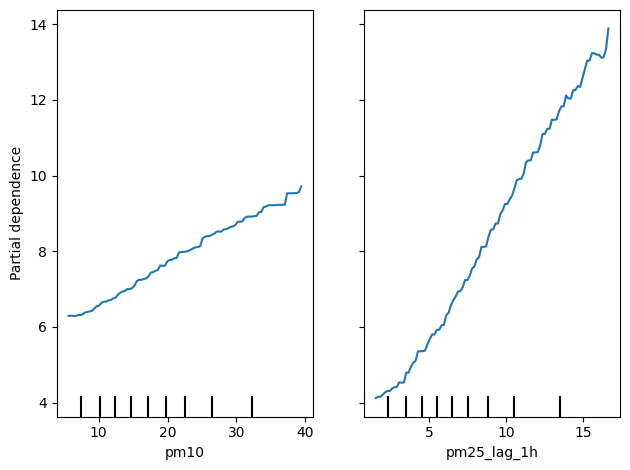

In [26]:
from sklearn.inspection import PartialDependenceDisplay

pdp_sample = X_val.sample(min(5000, len(X_val)), random_state=42)

PartialDependenceDisplay.from_estimator(
    lgbm_model,
    pdp_sample,
    ["pm10", "pm25_lag_1h"]
)

plt.tight_layout()
plt.show()

In [27]:
retention = pd.DataFrame([{
    "hourly_rows_loaded": len(hourly),
    "rows_with_pm25": hourly[target_col].notna().sum(),
    "rows_used_for_modelling": len(model_data),
    "pct_retained": round(100 * len(model_data) / len(hourly), 2),
}])
display(retention)

,hourly_rows_loaded,rows_with_pm25,rows_used_for_modelling,pct_retained
0,524592,454865,275847,52.58


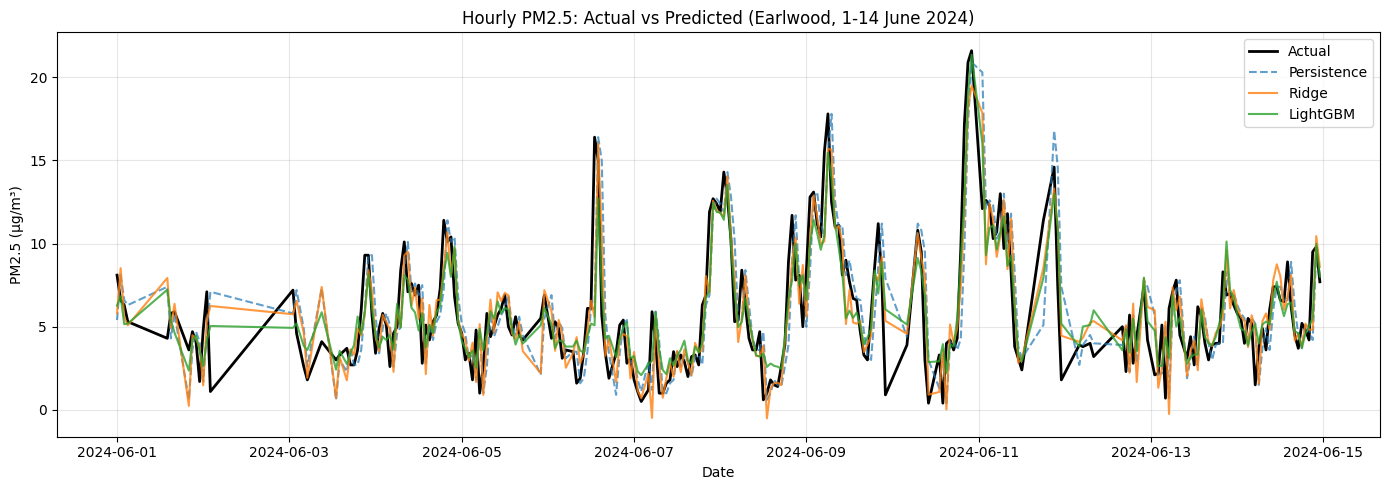

In [28]:
plot_df = val_data[["station", "datetime", "pm25"]].copy()
plot_df["Persistence"] = persistence_pred_val.values
plot_df["Ridge"] = ridge_pred_val
plot_df["LightGBM"] = lgbm_pred_val

sub = plot_df[(plot_df["station"] == "Earlwood") &
              (plot_df["datetime"] >= "2024-06-01") &
              (plot_df["datetime"] < "2024-06-15")]

plt.figure(figsize=(14, 5))
plt.plot(sub["datetime"], sub["pm25"], label="Actual", color="black", linewidth=2)
plt.plot(sub["datetime"], sub["Persistence"], label="Persistence", linestyle="--", alpha=0.7)
plt.plot(sub["datetime"], sub["Ridge"], label="Ridge", alpha=0.8)
plt.plot(sub["datetime"], sub["LightGBM"], label="LightGBM", alpha=0.8)
plt.title("Hourly PM2.5: Actual vs Predicted (Earlwood, 1-14 June 2024)")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
sample_size = min(10000, len(X_val))

importance_result = permutation_importance(
    lgbm_model,
    X_val.iloc[:sample_size],
    y_val.iloc[:sample_size],
    n_repeats=5,
    random_state=42,
    scoring="r2"
)

importance_table = (
    pd.DataFrame({
        "feature": feature_cols,
        "importance_mean_r2_drop": importance_result.importances_mean,
        "importance_std": importance_result.importances_std
    })
    .sort_values("importance_mean_r2_drop", ascending=False)
)

display(importance_table.round(6))

,feature,importance_mean_r2_drop,importance_std
11,pm25_lag_1h,0.980640,0.015727
0,pm10,0.101808,0.003323
12,pm25_lag_2h,0.084679,0.002542
13,pm25_lag_3h,0.022546,0.001556
1,temp,0.010135,0.000519
6,hour_sin,0.009648,0.000942
7,hour_cos,0.007567,0.000465
4,wdr,0.005514,0.000463
16,pm25_lag_24h,0.003972,0.000709
5,station_code,0.003834,0.000254


In [32]:
train_val_data = model_data[model_data["year"].between(2016, 2024)].copy()

X_train_val = train_val_data[feature_cols]
y_train_val = train_val_data[target_col]

final_hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=300,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

final_hgb_model.fit(X_train_val, y_train_val)

HistGradientBoostingRegressor(l2_regularization=1.0, learning_rate=0.08,
                              max_iter=300, random_state=42)

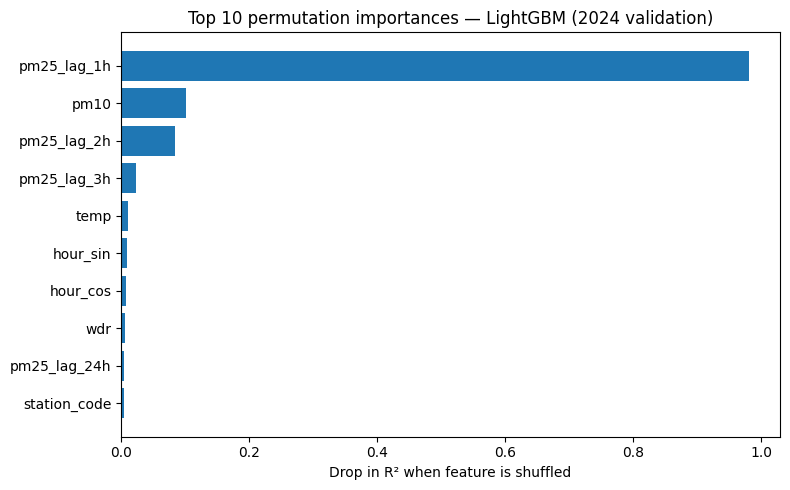

In [33]:
top = importance_table.head(10).iloc[::-1]

plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance_mean_r2_drop"])
plt.title("Top 10 permutation importances — LightGBM (2024 validation)")
plt.xlabel("Drop in R² when feature is shuffled")
plt.tight_layout()
plt.show()

In [37]:
feature_cols_no_pm10 = [col for col in feature_cols if col != "pm10"]

lgbm_no_pm10 = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.08,
    num_leaves=31,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1
)

lgbm_no_pm10.fit(train_data[feature_cols_no_pm10], y_train)

lgbm_no_pm10_pred_val = lgbm_no_pm10.predict(
    val_data[feature_cols_no_pm10]
)

lgbm_no_pm10_metrics_val = regression_metrics(
    y_val,
    lgbm_no_pm10_pred_val
)

sensitivity_results = pd.DataFrame([
    {"model": "LightGBM full feature set", **lgbm_metrics_val},
    {"model": "LightGBM excluding PM10", **lgbm_no_pm10_metrics_val}
])

display(sensitivity_results.round(4))

,model,MAE,RMSE,R2
0,LightGBM full feature set,1.9960,2.7112,0.7529
1,LightGBM excluding PM10,2.0874,2.8840,0.7204


In [40]:
# Refit LightGBM using both training and validation years
train_val_data = model_data[model_data["year"].between(2016, 2024)].copy()

X_train_val = train_val_data[feature_cols]
y_train_val = train_val_data[target_col]

final_lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.08,
    num_leaves=31,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
)

final_lgbm_model.fit(X_train_val, y_train_val)

LGBMRegressor(learning_rate=0.08, n_estimators=300, random_state=42,
              reg_lambda=1.0, verbose=-1)

In [43]:
test_pred = final_lgbm_model.predict(X_test)

test_results_df = pd.DataFrame([
    {
        "model": "LightGBM",
        "test_period": "2025",
        "rows": len(test_data),
        **regression_metrics(y_test, test_pred)
    }
])

display(test_results_df.round(4))

,model,test_period,rows,MAE,RMSE,R2
0,LightGBM,2025,27881,2.1285,2.9911,0.7496


In [42]:
tv_means = train_val_data.groupby(["station", "month"])[target_col].mean()

final_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X_train_val, y_train_val)
final_lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_val, y_train_val)
final_rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5,
                                 n_jobs=-1, random_state=42).fit(X_train_val, y_train_val)
final_lgbm = LGBMRegressor(n_estimators=300, learning_rate=0.08, num_leaves=31,
                           reg_lambda=1.0, random_state=42, verbose=-1).fit(X_train_val, y_train_val)

test_all = pd.DataFrame([
    {"model": "Seasonal mean (station-month)", **regression_metrics(y_test, seasonal_pred(test_data, tv_means))},
    {"model": "Persistence (PM2.5 t-1)", **regression_metrics(y_test, test_data["pm25_lag_1h"])},
    {"model": "Linear Regression", **regression_metrics(y_test, final_lr.predict(X_test))},
    {"model": "Ridge regression", **regression_metrics(y_test, final_ridge.predict(X_test))},
    {"model": "Random Forest", **regression_metrics(y_test, final_rf.predict(X_test))},
    {"model": "HistGradientBoosting", **regression_metrics(y_test, final_hgb_model.predict(X_test))},
    {"model": "LightGBM", **regression_metrics(y_test, final_lgbm.predict(X_test))},
]).sort_values("MAE").reset_index(drop=True)
display(test_all.round(4))
test_all.to_csv("test_results_2025.csv", index=False)

,model,MAE,RMSE,R2
0,LightGBM,2.1285,2.9911,0.7496
1,Random Forest,2.1562,3.0301,0.7430
2,HistGradientBoosting,2.1756,3.1590,0.7207
3,Ridge regression,2.3669,3.3612,0.6838
4,Linear Regression,2.3669,3.3612,0.6838
5,Persistence (PM2.5 t-1),2.5734,3.5950,0.6383
6,Seasonal mean (station-month),4.4369,6.0925,-0.0389
